# Multivariate analysis

In [1]:
import sys
import numpy as np
sys.path.append("..")
import matplotlib.pyplot as plt
import seaborn as sns
from src.data.loader import load_phenotypes
from src.config import MORE_EXPRESSED_GENES, L1_REGULATORS, L1_REGULATORS_WITH_2_STEPS_FROM_MECP2
from src.config import BrainRegions

In [2]:
df = load_phenotypes()

In [3]:
from src.data.loader import load_all_regions
import pandas as pd

regions = load_all_regions(nrows=None)

In [4]:
genes = []
for region, expr in regions.items():
    g = expr[expr["Description"].isin(L1_REGULATORS + MORE_EXPRESSED_GENES)]
    g = g.drop(columns="Name").melt(id_vars="Description", var_name="sample", value_name="TPM")
    g["region"] = region.value
    genes.append(g)

genes = pd.concat(genes)
print(genes.shape)
genes.head()

(352506, 4)


,Description,sample,TPM,region
0,KDM1A,GTEX-1117F-0011-R4b-SM-GI4VM,8.842710,amygdala
1,RUNX3,GTEX-1117F-0011-R4b-SM-GI4VM,0.967832,amygdala
2,PABPC4,GTEX-1117F-0011-R4b-SM-GI4VM,24.448600,amygdala
3,TUT4,GTEX-1117F-0011-R4b-SM-GI4VM,5.511600,amygdala
4,HENMT1,GTEX-1117F-0011-R4b-SM-GI4VM,3.591080,amygdala


In [5]:
genes["SUBJID"] = genes["sample"].str.split("-").str[:2].str.join("-")
genes = genes.merge(df[["SUBJID", "AGE"]], on="SUBJID")
genes.head()

,Description,sample,TPM,region,SUBJID,AGE
0,KDM1A,GTEX-1117F-0011-R4b-SM-GI4VM,8.842710,amygdala,GTEX-1117F,60-69
1,RUNX3,GTEX-1117F-0011-R4b-SM-GI4VM,0.967832,amygdala,GTEX-1117F,60-69
2,PABPC4,GTEX-1117F-0011-R4b-SM-GI4VM,24.448600,amygdala,GTEX-1117F,60-69
3,TUT4,GTEX-1117F-0011-R4b-SM-GI4VM,5.511600,amygdala,GTEX-1117F,60-69
4,HENMT1,GTEX-1117F-0011-R4b-SM-GI4VM,3.591080,amygdala,GTEX-1117F,60-69


In [6]:
ages = sorted(genes["AGE"].unique())

Causas de morte ordenadas pela quantidade de ocorrencias de tipo de morte para maior amostragem


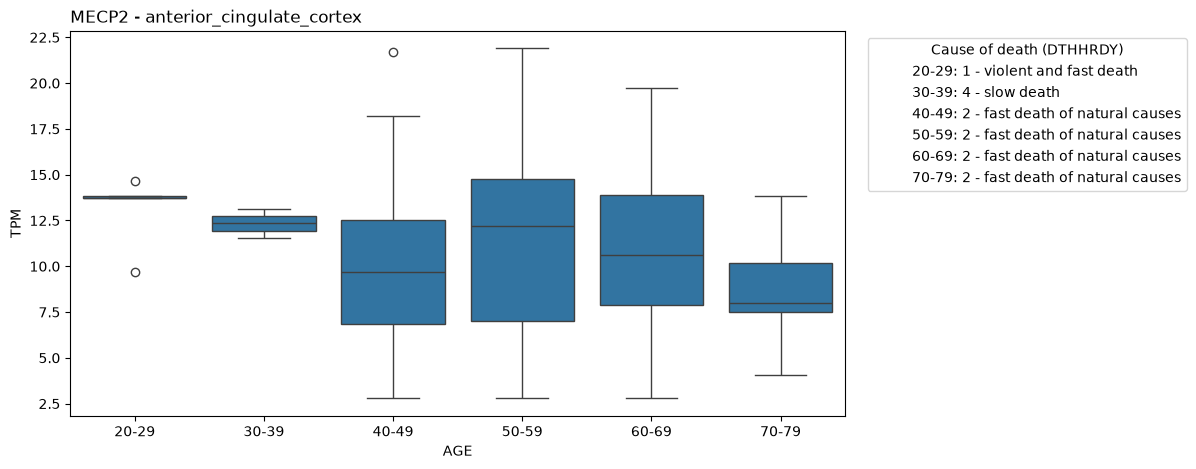

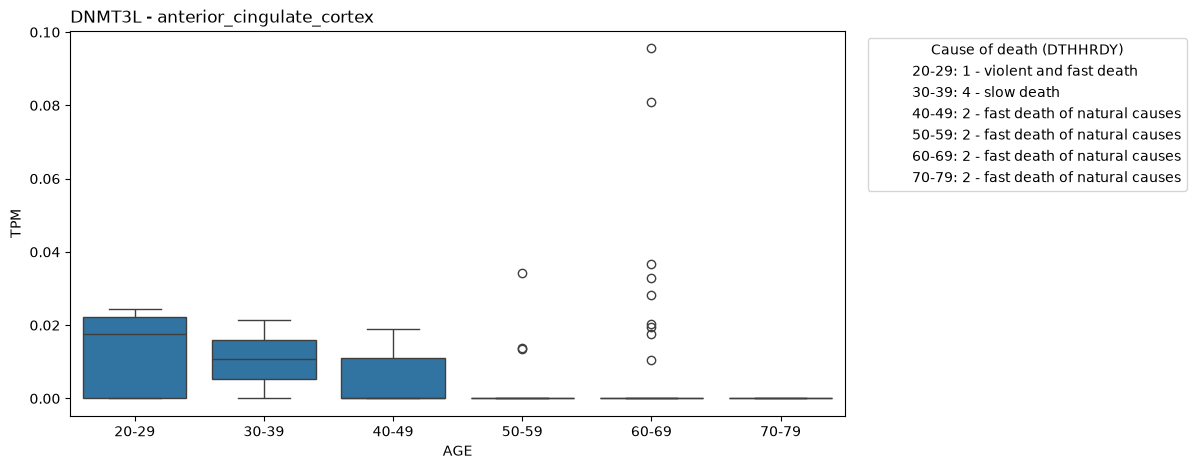

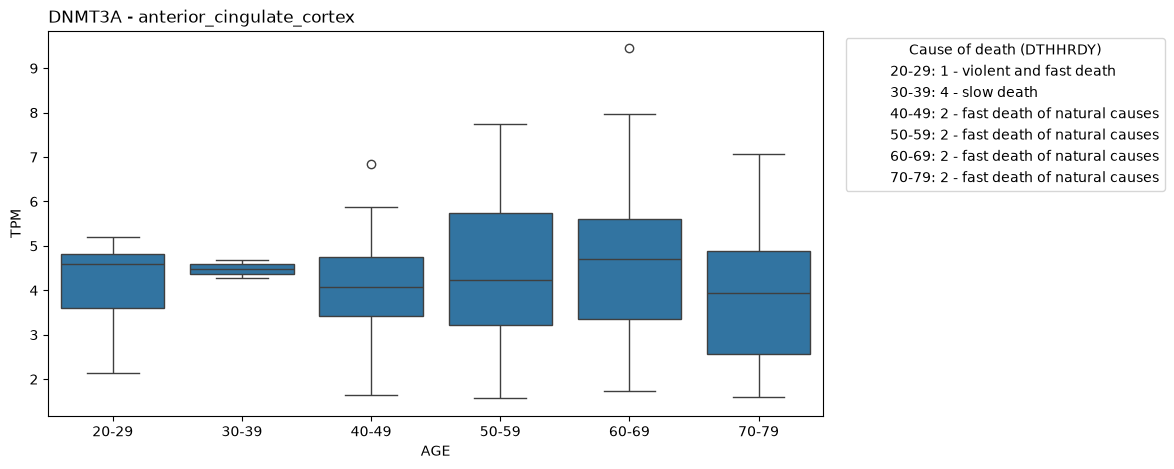

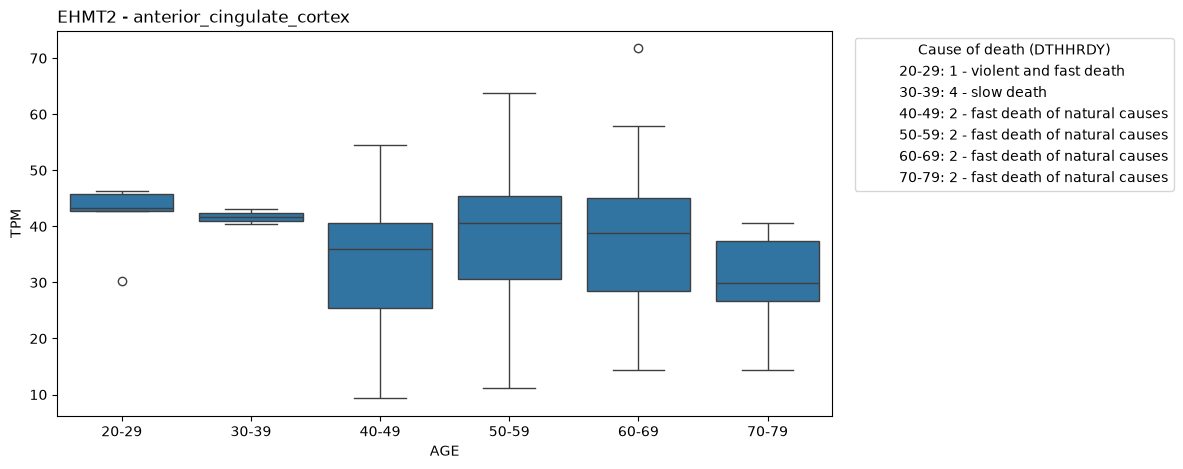

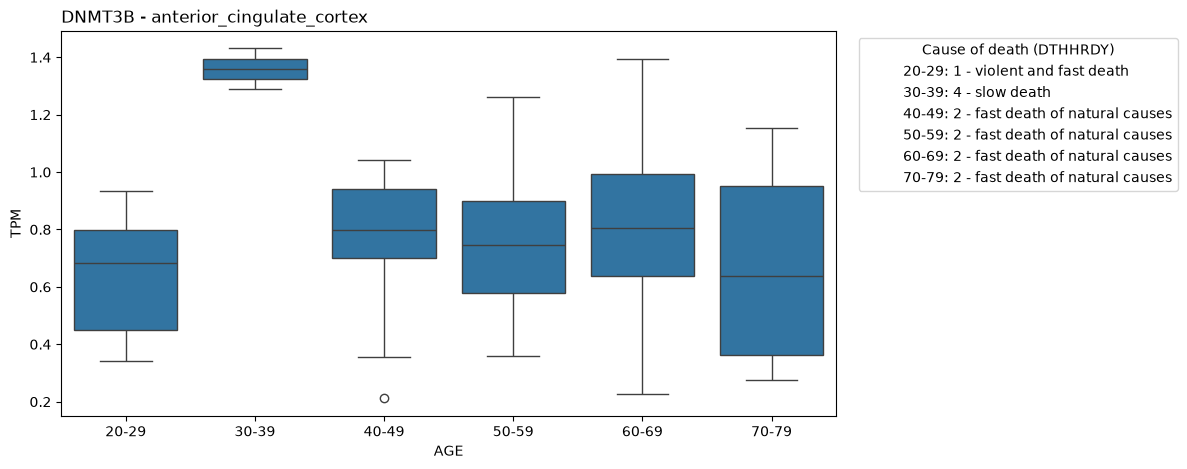

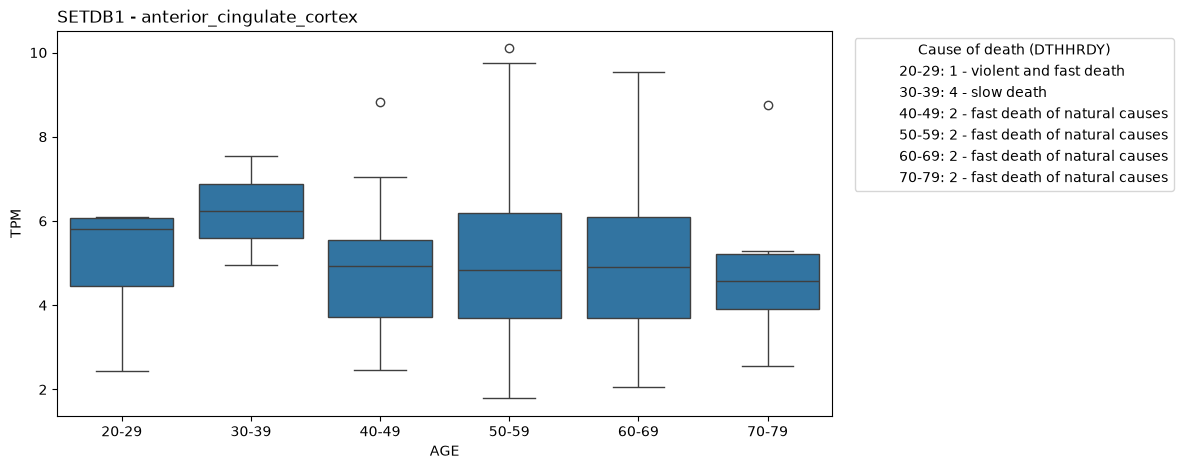

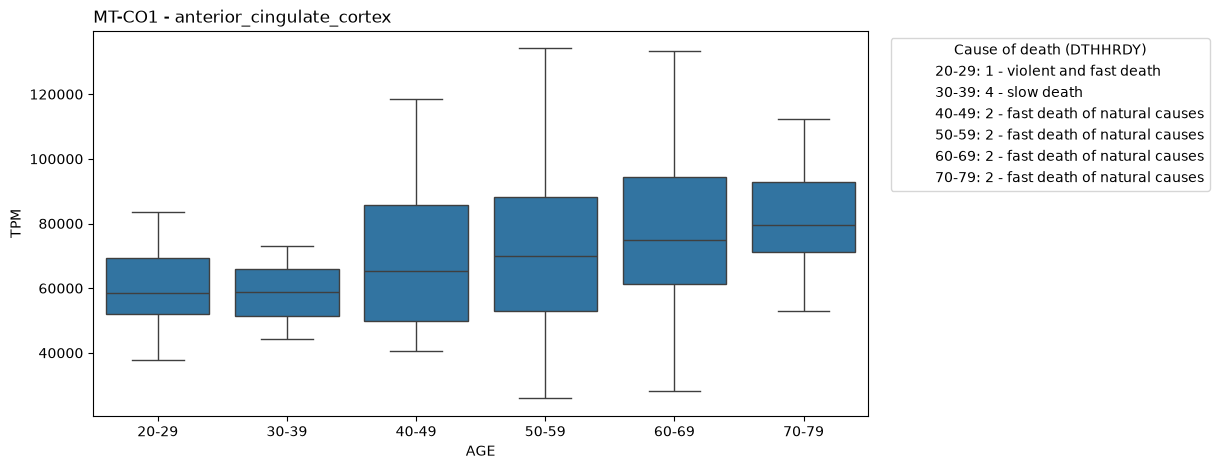

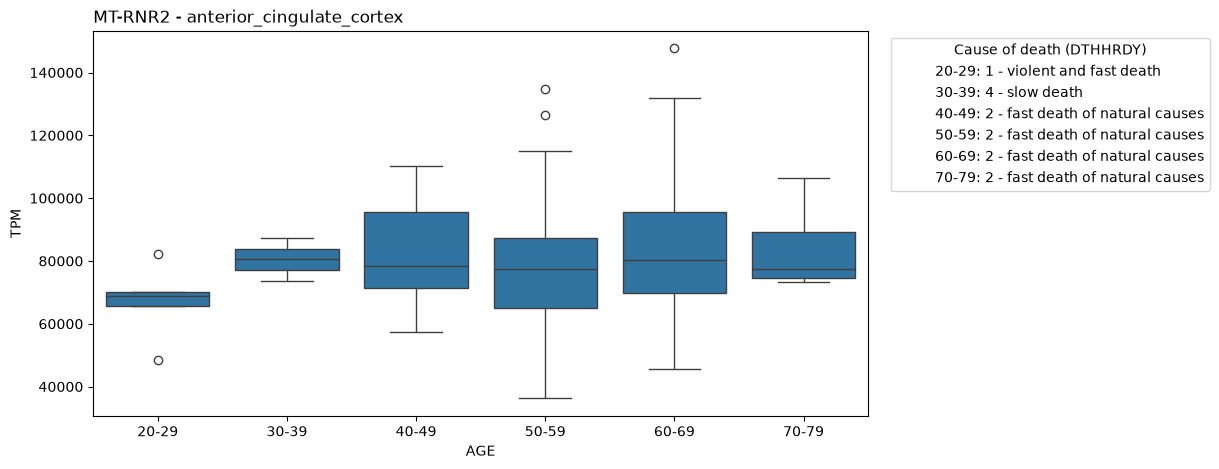

In [7]:
from matplotlib.patches import Patch

DEATH_PRIORITY = [2, 4, 3, 1, 0]
death_names = {
    0: "ventilator case",
    1: "violent and fast death",
    2: "fast death of natural causes",
    3: "intermediate death",
    4: "slow death",
}

cortex = genes[genes["region"] == "anterior_cingulate_cortex_ba24"].merge(df[["SUBJID", "SEX", "DTHHRDY"]], on="SUBJID")

same_death = []
death_by_age = {}
for age in ages:
    age_samples = cortex[cortex["AGE"] == age]
    death = next(d for d in DEATH_PRIORITY if age_samples[age_samples["DTHHRDY"] == d]["SEX"].nunique() == 2)
    death_by_age[age] = death
    same_death.append(age_samples[age_samples["DTHHRDY"] == death])
cortex = pd.concat(same_death)

for gene in L1_REGULATORS_WITH_2_STEPS_FROM_MECP2 + MORE_EXPRESSED_GENES:
    plt.figure(figsize=(10, 5))
    sns.boxplot(data=cortex[cortex["Description"] == gene], x="AGE", y="TPM", order=ages)
    plt.title(f"{gene} - anterior_cingulate_cortex", loc="left")
    plt.legend(
        handles=[Patch(color="none", label=f"{age}: {d} - {death_names[d]}") for age, d in death_by_age.items()],
        title="Cause of death (DTHHRDY)",
        bbox_to_anchor=(1.02, 1),
        loc="upper left",
    )
    plt.show()

Visualizar como os genes regulares e os genes mais expressos se comportam em TPM conforme a pessoa envelhece.
Na visualizaçao vemos que quanto mais o indivíduo invelhece mais ao nivel de expressão varia como é possivel ver nos genes MECP2 e MT-RNR2 que são os casos mais extremos. Visualizamos tambem uma diferença de comportamento no DNMT3B que pode estar ligado a causa de morte.

In [8]:
expression = pd.concat(
    [expr.set_index(["Name", "Description"]) for expr in regions.values()], axis=1
)
expression.shape

(74628, 3234)

In [9]:
rows = []
for region, expr in regions.items():
    region_variance = expr.set_index("Description").drop(columns="Name").var(axis=1).sort_values(ascending=False)
    rows.append({
        "region": region.value,
        "most_variable": region_variance.index[0],
        "max_variance": region_variance.iloc[0],
        "least_variable": region_variance.index[-1],
        "min_variance": region_variance.iloc[-1],
        "genes_with_zero_variance": (region_variance == 0).sum(),
    })

variance_by_region = pd.DataFrame(rows)
variance_by_region

,region,most_variable,max_variance,least_variable,min_variance,genes_with_zero_variance
0,amygdala,MT-CO1,5.152518e+08,MIR3153,0.0,6402
1,anterior_cingulate_cortex_ba24,MT-CO1,5.976916e+08,RNU6-1252P,0.0,5321
2,caudate_basal_ganglia,MT-CO1,5.436034e+08,EP400P1,0.0,4595
3,cerebellar_hemisphere,MT-CO1,5.788917e+08,MIR6724-1,0.0,5112
4,cerebellum,MT-CO1,3.677860e+08,ENSG00000305859,0.0,4866
5,cortex,MT-RNR2,3.221917e+08,ENSG00000309285,0.0,4547
6,frontal_cortex_ba9,MT-RNR2,5.523009e+08,ENSG00000308840,0.0,4884
7,hippocampus,MT-CO1,6.216196e+08,ENSG00000252989,0.0,4438
8,hypothalamus,MT-CO1,6.580027e+08,ENSG00000244669,0.0,4667
9,nucleus_accumbens_basal_ganglia,MT-CO1,5.732477e+08,ENSG00000294933,0.0,4561


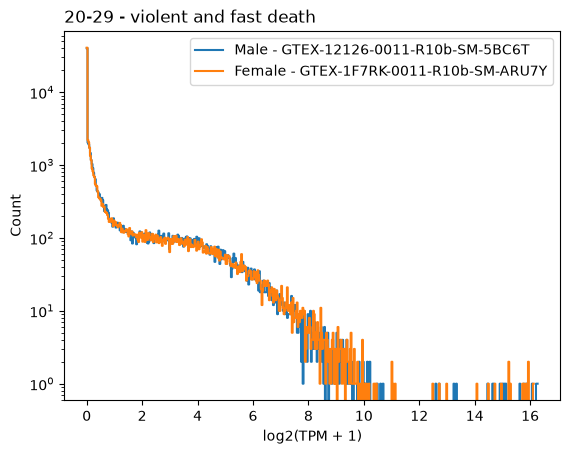

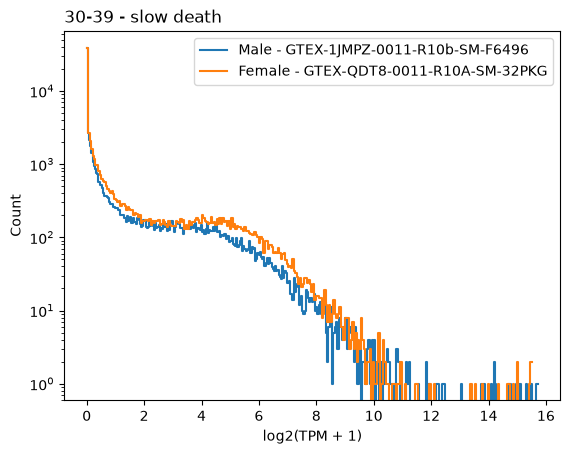

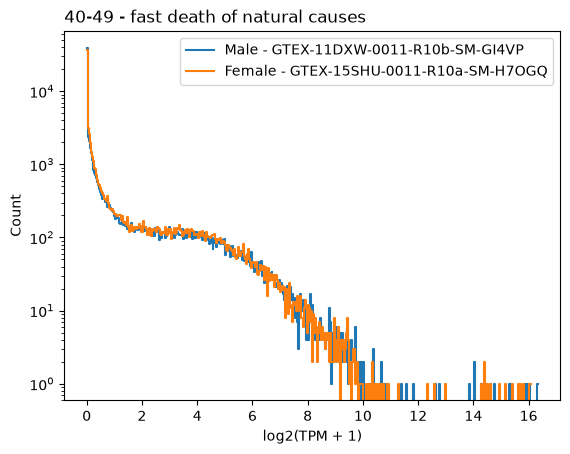

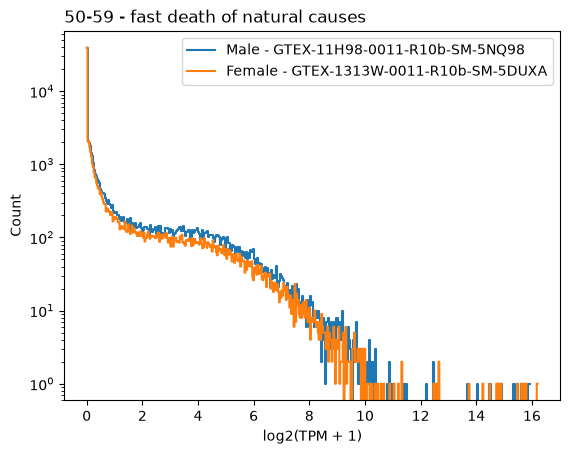

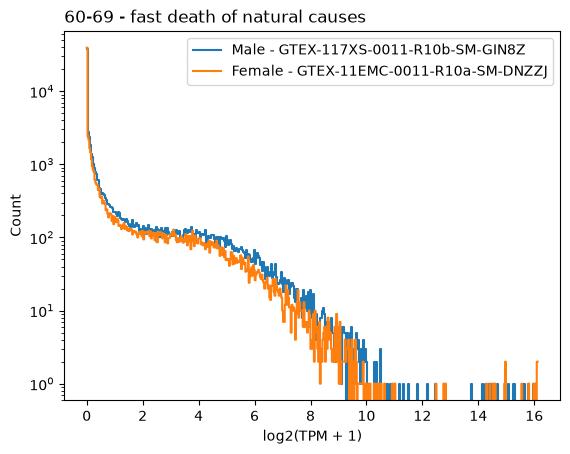

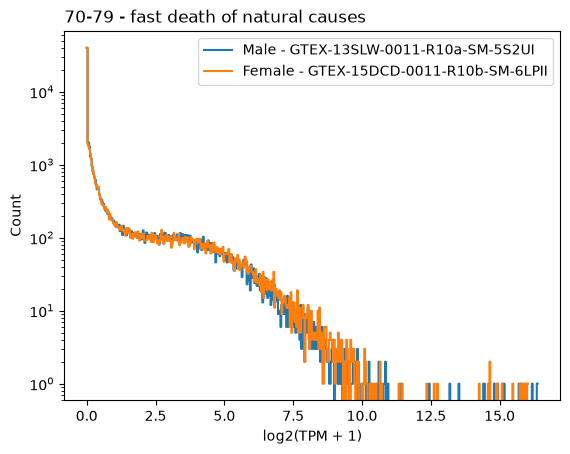

In [10]:
donors = expression.columns.str.split("-").str[:2].str.join("-")
samples = pd.DataFrame({
    "sample": expression.columns,
    "AGE": donors.map(df.set_index("SUBJID")["AGE"]),
    "SEX": donors.map(df.set_index("SUBJID")["SEX"].replace({1: "Male", 2: "Female"})),
    "DTHHRDY": donors.map(df.set_index("SUBJID")["DTHHRDY"]),
})
frontal_cortex_samples = regions[BrainRegions.FRONTAL_CORTEX_BA9].columns[2:]
samples = samples[samples["sample"].isin(frontal_cortex_samples)]

one_sample_per_age_sex = samples.groupby(["AGE", "DTHHRDY", "SEX"])["sample"].first()

for age in sorted(samples["AGE"].unique()):
    death = next(
        (d for d in DEATH_PRIORITY if all((age, d, sex) in one_sample_per_age_sex for sex in ["Male", "Female"])),
        None,
    )
    if death is None:
        print(f"{age}: no male and female sample with the same DTHHRDY")
        continue

    for sex in ["Male", "Female"]:
        sample = one_sample_per_age_sex[(age, death, sex)]
        sns.histplot(np.log2(expression[sample] + 1), element="step", fill=False, label=f"{sex} - {sample}")
    plt.title(f"{age} - {death_names[death]}", loc="left")
    plt.xlabel("log2(TPM + 1)")
    plt.legend()
    plt.yscale("log")
    plt.show()

Nao é possivel dizer que o nivel de expressão tem relaçao direta com sexos diferentes tendo mesma regiao do cerebro e mesma causa de morte. É possivel ver um leve aumento de expressão do sexo masculino na faixa etária de 50 a 69 anos, só que nao é possivel saber se é algo individual ou geral.

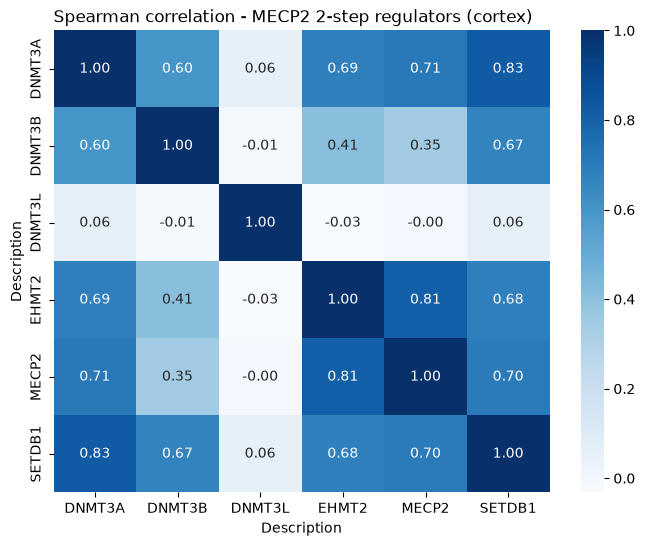

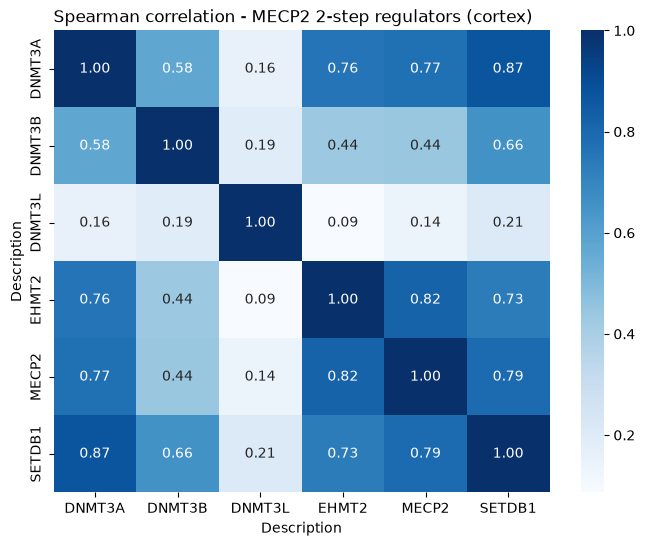

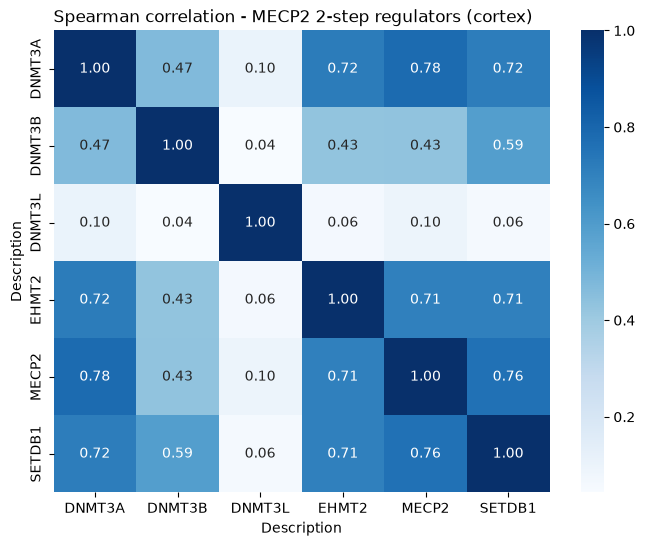

In [11]:
for region in ["cortex", "frontal_cortex_ba9", "cerebellum"]:

    mecp2_regulators = genes[genes["Description"].isin(L1_REGULATORS_WITH_2_STEPS_FROM_MECP2) & (genes["region"] == region)]
    mecp2_regulators = mecp2_regulators.pivot(index="sample", columns="Description", values="TPM")

    corr = mecp2_regulators.corr(method="spearman")

    plt.figure(figsize=(8, 6))
    sns.heatmap(corr, annot=True, fmt=".2f", cmap="Blues")
    plt.title("Spearman correlation - MECP2 2-step regulators (cortex)", loc="left")
    plt.show()

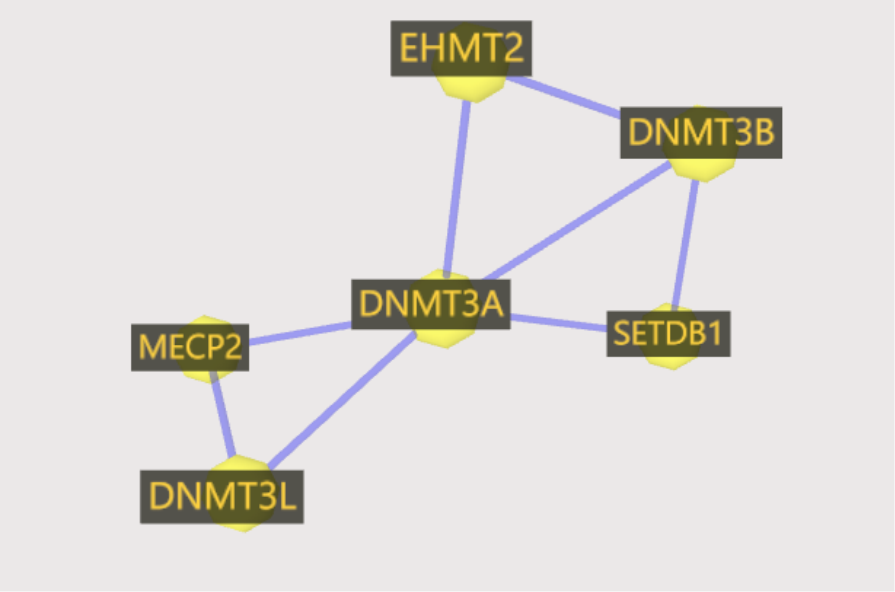

In [12]:
from IPython.display import Image

Image("../reports/figures/mecp2_regulators_network.png")

Com pesquisas anteriores verificamos que o DNMT3A faz a ponte com MECP2 gerando uma ligaçao fisica e funcional com os genes EHMT2, DNMT3B, E SETDB1. Diferentemente do DNMT3L que possui uma relação direta com esse mesmo papel fisico e funcional que conseguimos vizualizar em diferentes regiões do cérebro. Sendo SETDB1 possuindo a maior correlação dentre o grupo. Que é esse tipo de relaçao que queremos encontrar com o modelo ao fim do processo.

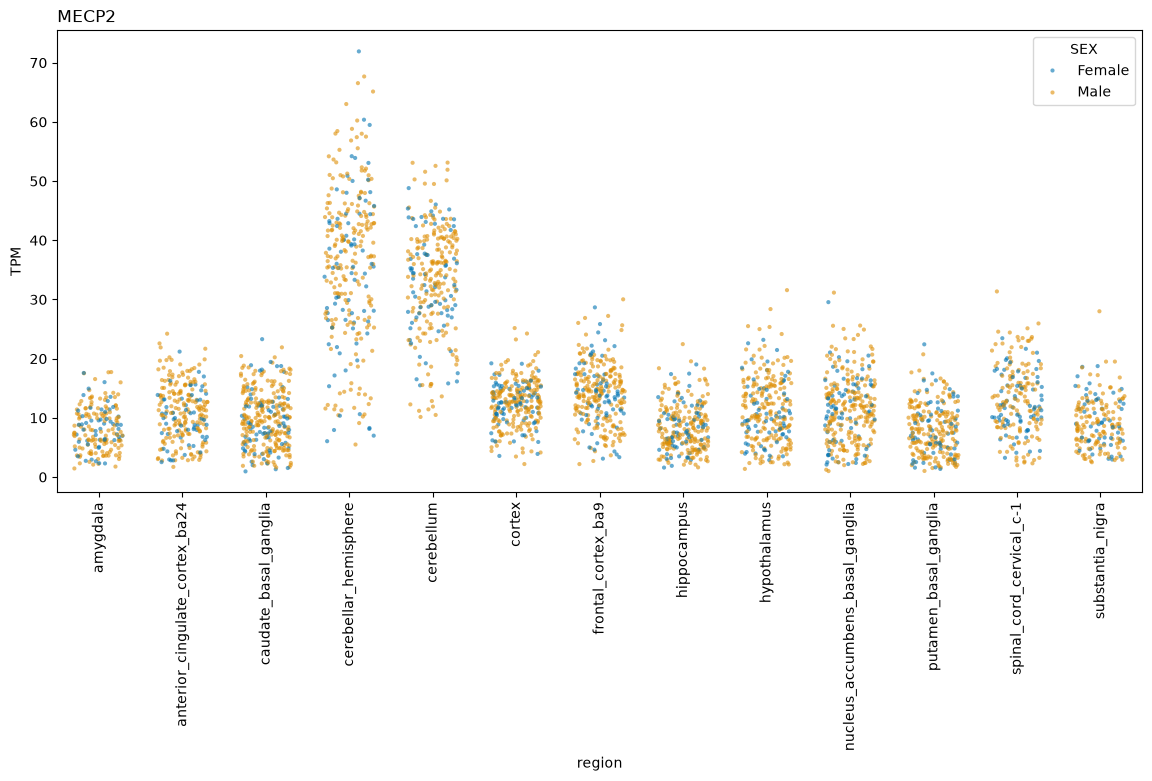

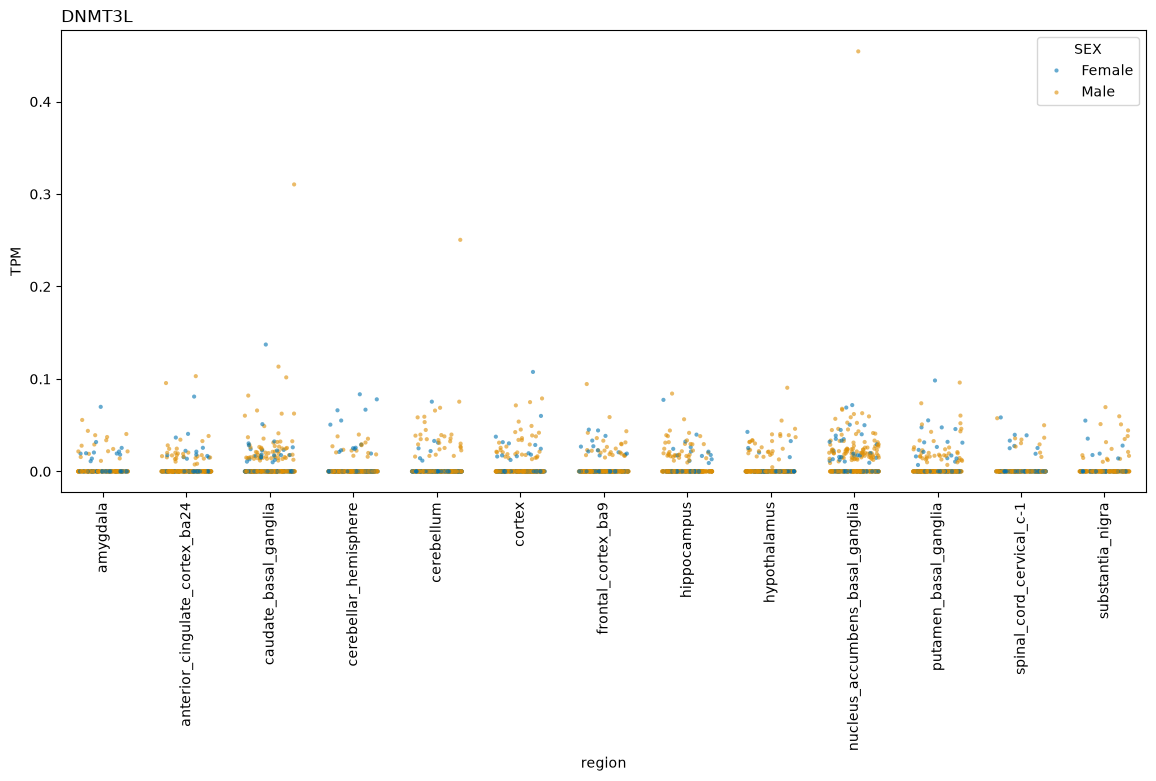

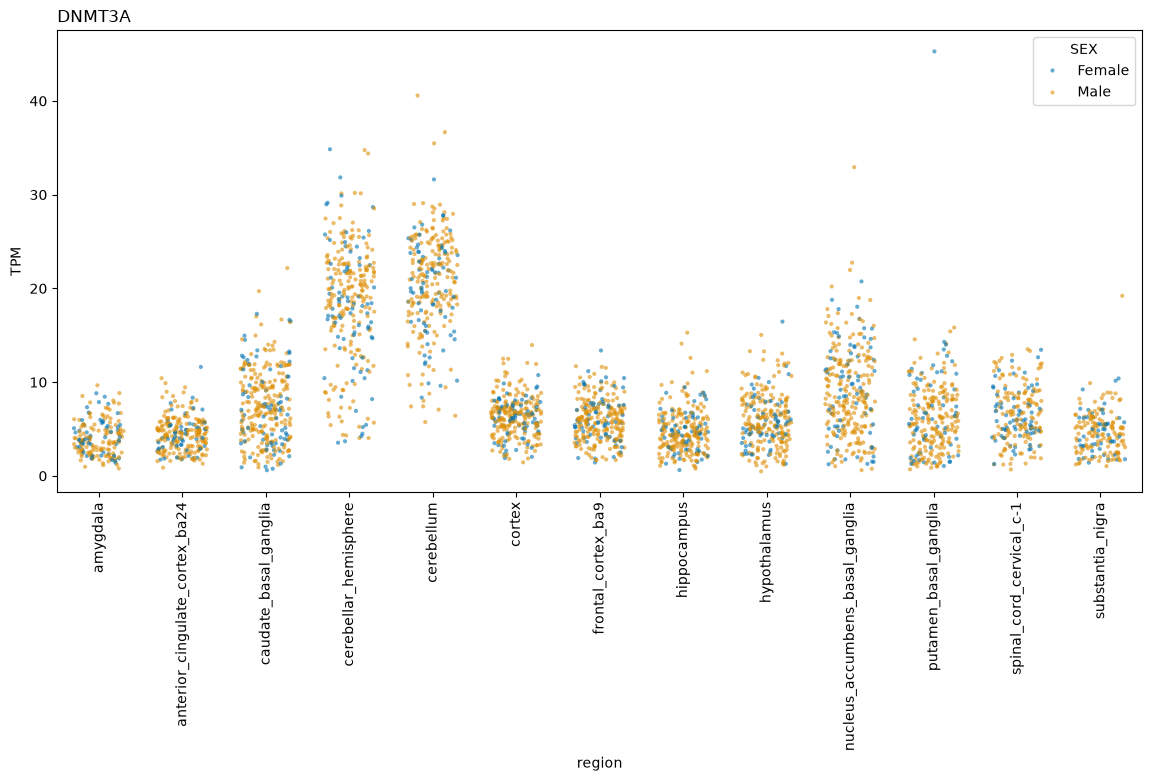

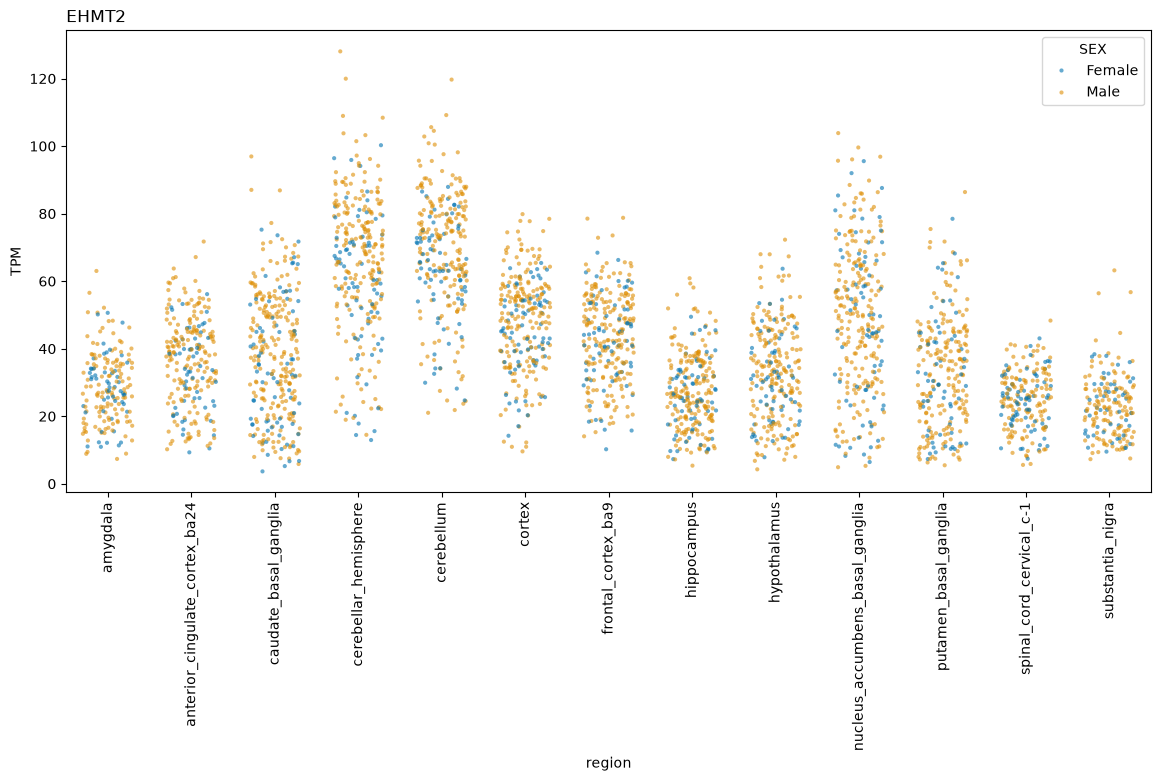

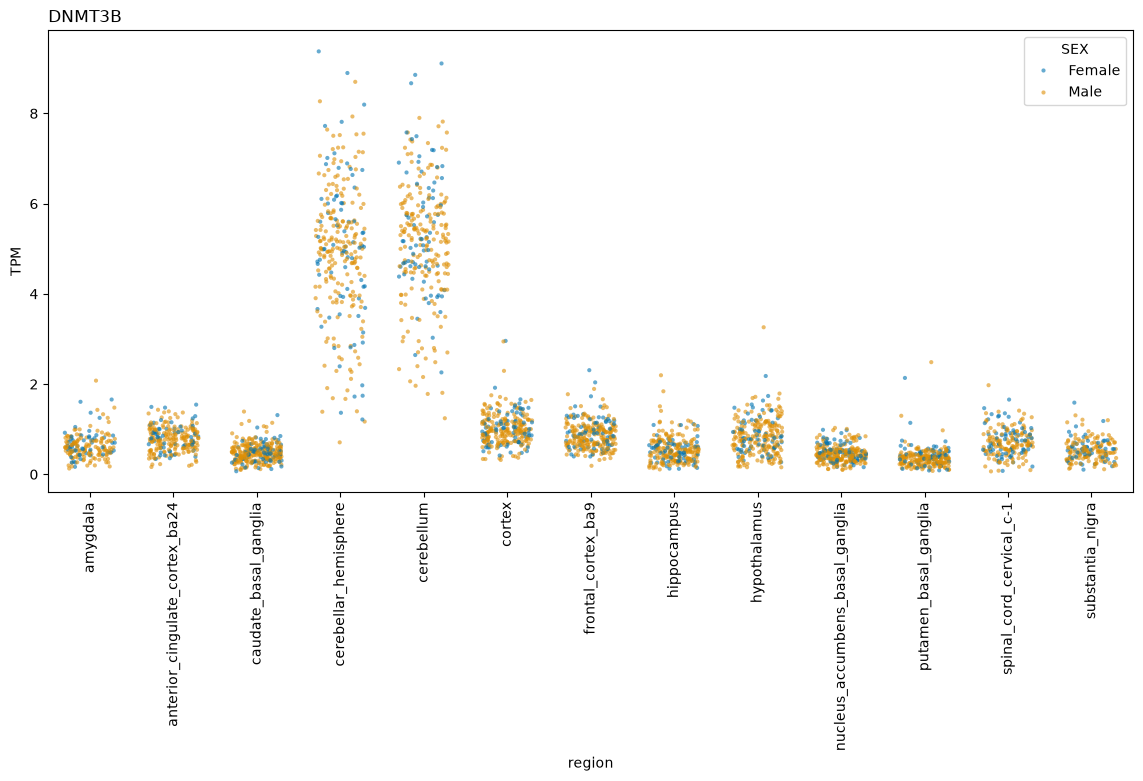

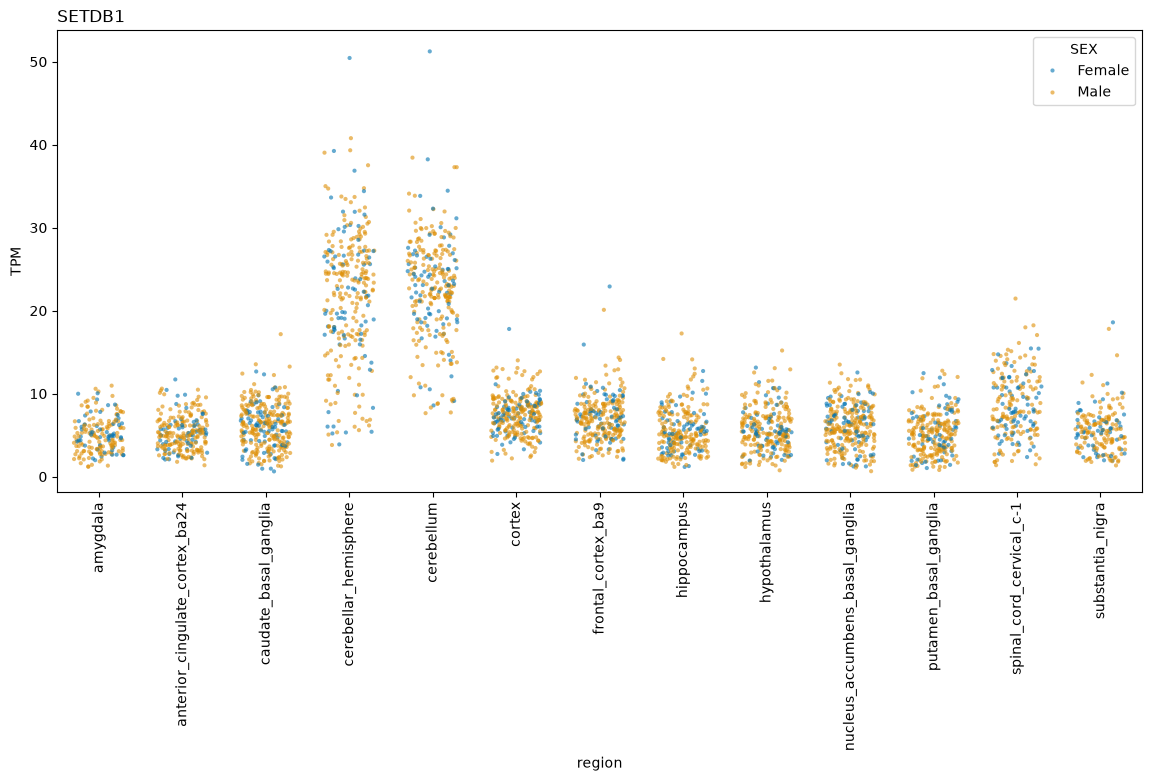

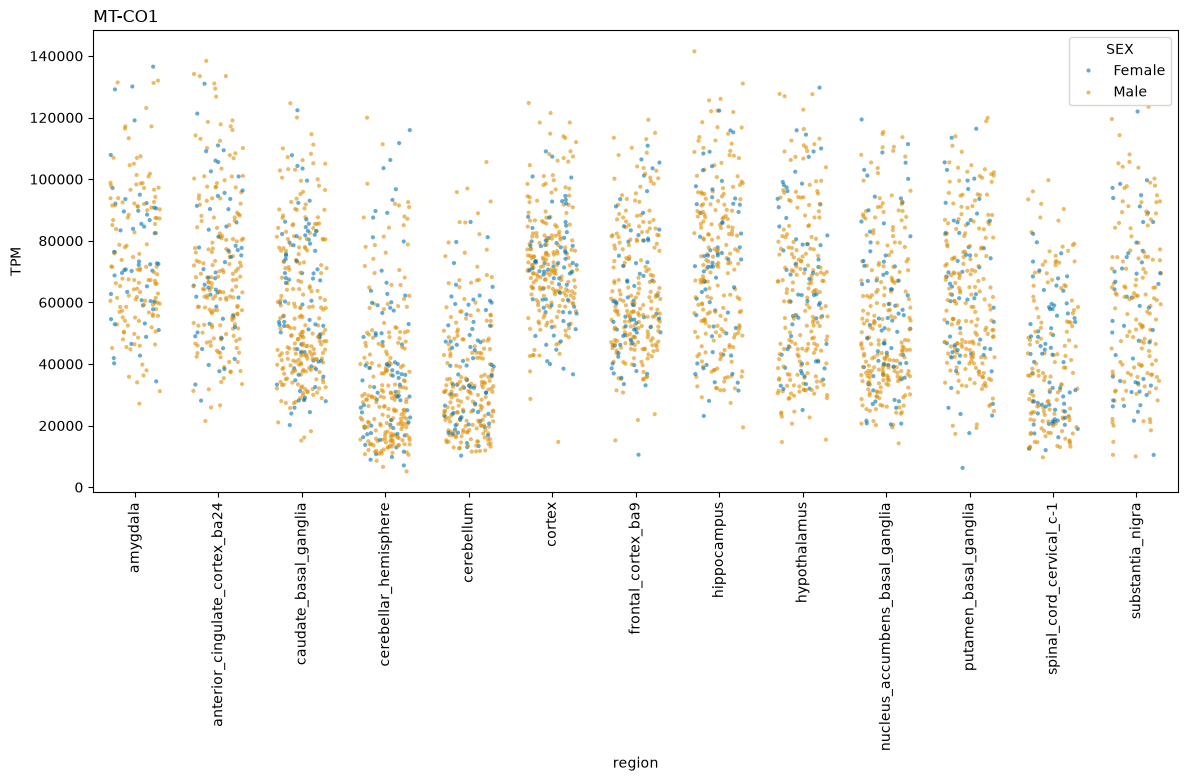

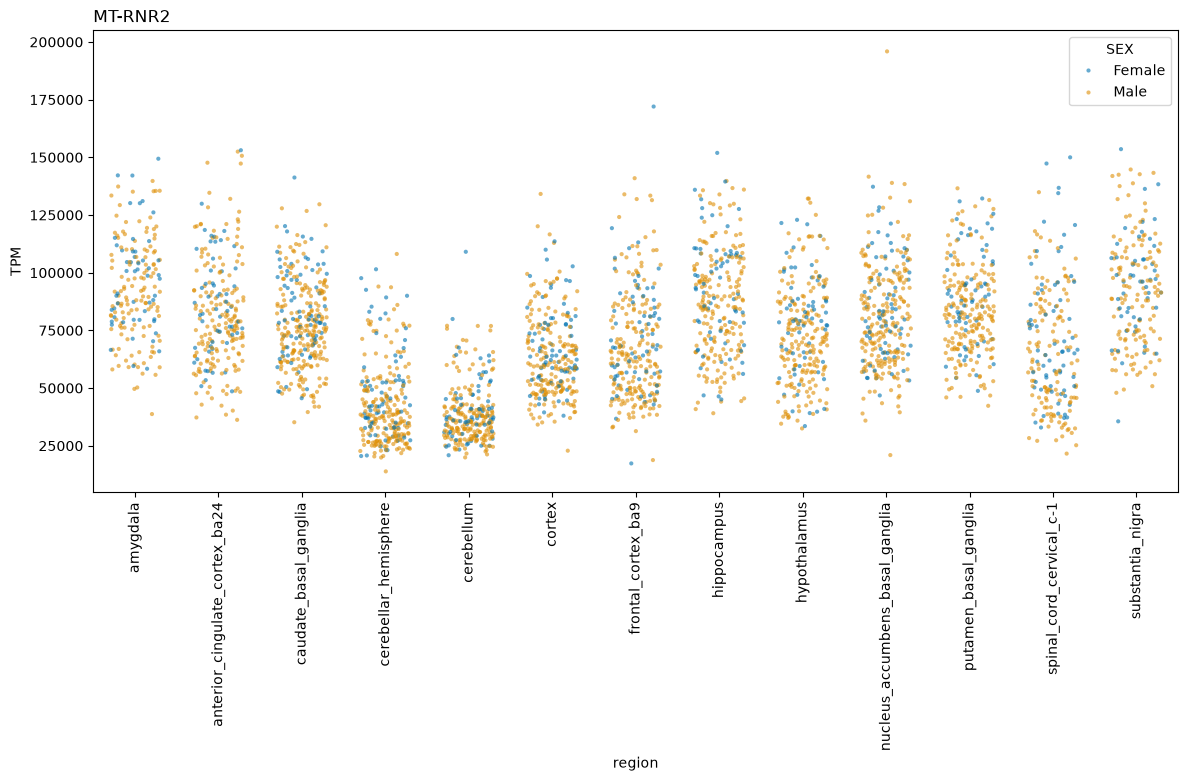

In [13]:

genes_sex = genes.merge(df[["SUBJID", "SEX"]], on="SUBJID")
genes_sex["SEX"] = genes_sex["SEX"].replace({1: "Male", 2: "Female"})

for gene in L1_REGULATORS_WITH_2_STEPS_FROM_MECP2 + MORE_EXPRESSED_GENES:
    plt.figure(figsize=(14, 6))
    sns.stripplot(
        data=genes_sex[genes_sex["Description"] == gene], x="region", y="TPM",
        hue="SEX", palette="colorblind",
        jitter=0.3, alpha=0.6, s=3,
    )
    plt.xticks(rotation=90)
    plt.title(gene, loc="left")
    plt.legend(title="SEX", bbox_to_anchor=(1, 1))
    plt.show()

conseguimos ver que o grupo de reguladores tem um nivel de expressao muito maior nas regioes cerebellum e cerebellar hemisphere.

**Papel do cerebelo (cerebellum e cerebellar hemisphere)**

 O cerebelo é mais conhecido pela coordenação motora: ele ajusta a precisão, o tempo e o equilíbrio dos movimentos e participa do aprendizado motor. (Schmahmann & Sherman, 1998; Buckner, 2013).

Um ponto que ajuda a entender a expressão mais alta nessas duas regiões é a composição celular. O cerebelo concentra cerca de 80% de todos os neurônios do cérebro humano, a maior parte deles células granulares pequenas e muito densas (Azevedo et al., 2009; Herculano-Houzel, 2010). Por isso o perfil de expressão do cerebelo costuma ser bem diferente do restante do cérebro.

No GTEx, "Brain - Cerebellum" e "Brain - Cerebellar Hemisphere" são consideradas duplicatas da mesma região. Uma foi coletada no momento da doação e preservada em PAXgene, e a outra foi coletada depois, no banco de cérebros, e congelada (GTEx FAQ). Isso explica por que as duas aparecem com padrões de expressão parecidos.

**Referências**

- Schmahmann, J. D., & Sherman, J. C. (1998). The cerebellar cognitive affective syndrome. *Brain*, 121(4), 561–579. https://doi.org/10.1093/brain/121.4.561
- Buckner, R. L. (2013). The cerebellum and cognitive function: 25 years of insight from anatomy and neuroimaging. *Neuron*, 80(3), 807–815. https://doi.org/10.1016/j.neuron.2013.10.044
- Azevedo, F. A. C., et al. (2009). Equal numbers of neuronal and nonneuronal cells make the human brain an isometrically scaled-up primate brain. *Journal of Comparative Neurology*, 513(5), 532–541. https://doi.org/10.1002/cne.21974
- Herculano-Houzel, S. (2010). Coordinated scaling of cortical and cerebellar numbers of neurons. *Frontiers in Neuroanatomy*, 4, 12. https://doi.org/10.3389/fnana.2010.00012
- GTEx Portal. Frequently Asked Questions. https://sites.google.com/broadinstitute.org/gtex-faqs/home


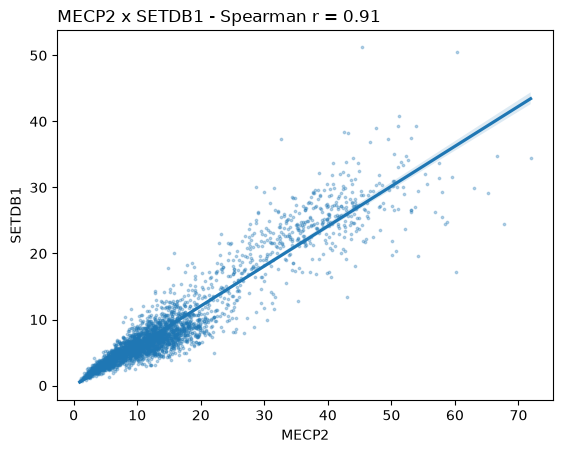

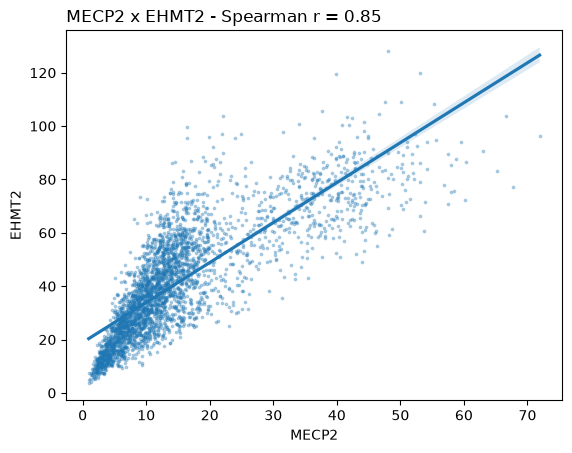

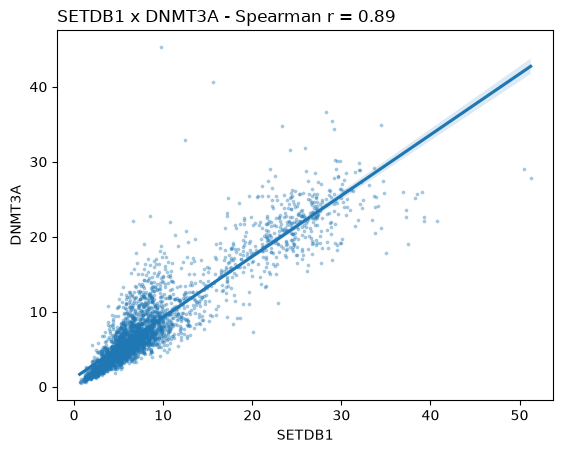

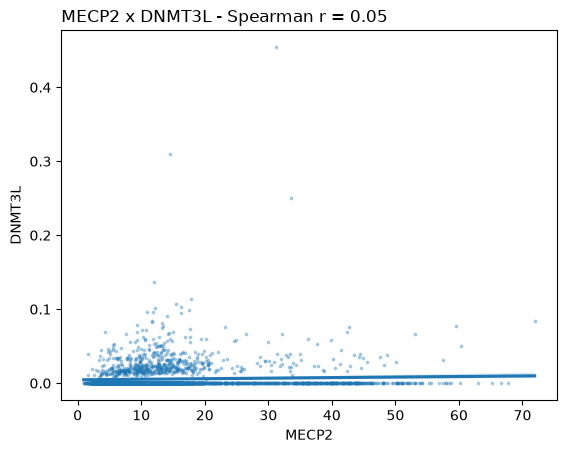

In [14]:
regulators = genes[genes["Description"].isin(L1_REGULATORS_WITH_2_STEPS_FROM_MECP2)]
regulators = regulators.pivot(index="sample", columns="Description", values="TPM")

for x, y in [("MECP2", "SETDB1"), ("MECP2", "EHMT2"), ("SETDB1", "DNMT3A"), ("MECP2", "DNMT3L")]:
    r = regulators[x].corr(regulators[y], method="spearman")
    sns.regplot(data=regulators, x=x, y=y, scatter_kws={"s": 3, "alpha": 0.3})
    plt.title(f"{x} x {y} - Spearman r = {r:.2f}", loc="left")
    plt.show()

Como vimos anteriormente a correlaçao é positiva na maioria dos genes. tirando o DNMT3L que não possui correlaçao por fazer parte do desenvolvimento embrionário e nas células germinativas que acaba não sendo expresso em adultos.